# Lab 6 — Text Classification Using Neural Networks

**Completed adaptation of the U of T DSI `deep_learning/01_materials/labs/lab_6.ipynb`**. The steps follow the original notebook's progression:

1. Load and inspect the five-topic BBC dataset.
2. Establish a `CountVectorizer + LogisticRegression` baseline.
3. Tokenize and pad news documents.
4. Train a supervised CBOW-style model using learned embeddings.
5. **Exercise 1:** evaluate on test set and display a misclassified document.
6. **Exercise 2:** build and evaluate a more complex `Conv1D` neural network.
7. Download and explore pre-trained GloVe embeddings, visualize t-SNE.
8. Use frozen GloVe embeddings in a neural network and compare results.


## 0. Set up TensorFlow / CPU

Your Intel Mac can run this lesson without CUDA; GPU availability is not required.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path

try:
    tf.config.set_visible_devices([], 'GPU')
except RuntimeError:
    # Already initialized: do not change device settings mid-session.
    pass

tf.keras.utils.set_random_seed(42)
print('TensorFlow:', tf.__version__)
print('Available GPU devices:', tf.config.list_physical_devices('GPU'))

2026-11-17 15:07:01.672904: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.16.2
Available GPU devices: []


## 1. The BBC topic classification dataset

The BBC news text corpus includes five news topics (business, entertainment, politics, sport, tech). The source notebook uses the BBC full-text ZIP from University College Dublin. These historical articles are **not current news**, and this is an educational topic-classification task.

The downloaded archive is extracted locally into `bbc/`. If the older download host is temporarily unavailable, manually download the raw-text ZIP from the [BBC Datasets page](https://derekgreene.com/bbc/) and put `bbc-fulltext.zip` in the Notebook's current working directory. The original source is `http://mlg.ucd.ie/files/datasets/bbc-fulltext.zip`.

In [2]:
import os.path as op
from urllib.request import urlretrieve
import zipfile

ZIP_FILENAME = Path('bbc-fulltext.zip')
BBC_FOLDER = Path('bbc')
BBC_URLS = [
    'https://mlg.ucd.ie/files/datasets/bbc-fulltext.zip',
    'http://mlg.ucd.ie/files/datasets/bbc-fulltext.zip',
]
if not BBC_FOLDER.is_dir():
    if not ZIP_FILENAME.is_file():
        last_error = None
        for url in BBC_URLS:
            try:
                print('Downloading BBC text dataset from', url)
                urlretrieve(url, ZIP_FILENAME)
                last_error = None
                break
            except Exception as exc:
                last_error = exc
                if ZIP_FILENAME.exists():
                    ZIP_FILENAME.unlink()  # remove incomplete file
                print('Download failed, trying another source:', type(exc).__name__)
        if last_error is not None:
            raise RuntimeError(
                'BBC download unavailable. Download bbc-fulltext.zip manually from '
                'https://derekgreene.com/bbc/ into the current working directory '
                'and re-run this cell.'
            ) from last_error
    with zipfile.ZipFile(ZIP_FILENAME) as archive:
        for member in archive.infolist():
            target = (Path.cwd() / member.filename).resolve()
            if not target.is_relative_to(Path.cwd().resolve()):
                raise ValueError('Unsafe path in archive')
        archive.extractall(Path.cwd())

if not BBC_FOLDER.is_dir():
    raise FileNotFoundError('Expected bbc/ directory after extraction')
print('BBC dataset:', BBC_FOLDER.resolve())

Download failed, trying another source: URLError
BBC dataset: /Users/lvsburgerl/Documents/UOFT DSI MACHINE LEARNING FALL 2026/deep_learning/01_materials/labs/bbc


The five subfolders represent the target classes.

In [3]:
target_names = sorted(p.name for p in BBC_FOLDER.iterdir() if p.is_dir())
print('Topics:', target_names)
assert len(target_names) == 5, 'Expected five BBC news categories'

Topics: ['business', 'entertainment', 'politics', 'sport', 'tech']


In [4]:
# Inspect the opening of the first document in business.
example_path = BBC_FOLDER / 'business' / '001.txt'
with open(example_path, 'rb') as f:
    print(f.read().decode('latin-1')[:500] + '...')

Ad sales boost Time Warner profit

Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (Â£600m) for the three months to December, from $639m year-earlier.

The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn. Its profits were buoyed by one-off gains which offset a profit dip at Warner Bros, and less users for AOL.

Time ...


### Train/test split

Create one fixed random split of 200 test documents. Keep documents from the test set out of vocabulary fitting and model training to prevent data leakage.

In [5]:
from sklearn.model_selection import train_test_split

filenames, target = [], []
for category_id, category in enumerate(target_names):
    for fn in sorted((BBC_FOLDER / category).glob('*.txt')):
        filenames.append(str(fn))
        target.append(category_id)
target = np.array(target, dtype=np.int32)

target_train, target_test, filenames_train, filenames_test = train_test_split(
    target, filenames, test_size=200, random_state=0,
    stratify=target
)
print('Train documents:', len(target_train))
print('Test documents:', len(target_test))
print('Class mapping:', dict(enumerate(target_names)))

Train documents: 2025
Test documents: 200
Class mapping: {0: 'business', 1: 'entertainment', 2: 'politics', 3: 'sport', 4: 'tech'}


In [6]:
print('Sample labels:', target_train[:5])
print('Sample paths:', filenames_train[:5])
size_in_bytes = sum(os.path.getsize(fn) for fn in filenames_train)
print('Training set size: %.3f MB' % (size_in_bytes / 1e6))

Sample labels: [1 4 0 0 3]
Sample paths: ['bbc/entertainment/205.txt', 'bbc/tech/352.txt', 'bbc/business/077.txt', 'bbc/business/365.txt', 'bbc/sport/108.txt']
Training set size: 4.573 MB


The corpus fits into RAM on a laptop. For a much larger corpus, a streaming `tf.data.Dataset` pipeline would be preferable.

In [7]:
def load_text(fn):
    with open(fn, 'rb') as f:
        return f.read().decode('latin-1')

texts_train = [load_text(fn) for fn in filenames_train]
texts_test = [load_text(fn) for fn in filenames_test]
print('Example document length:', len(texts_train[0]))

Example document length: 1343


## 2. A first baseline model — Bag of words and Logistic Regression

`CountVectorizer` maps documents to word-count vectors. Logistic regression maps those features to one of five topics. This gives a fast baseline for comparison with neural networks.

In [8]:
from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer(max_features=2000)
X_bow_train = vectorizer.fit_transform(texts_train)
print('First document:', texts_train[0][:100] + '...')
print('Word-count examples:')
for word, count in zip(vectorizer.get_feature_names_out()[200:210],
                       X_bow_train.toarray()[0][200:210]):
    print(word, count)
print('Bag-of-words matrix shape:', X_bow_train.shape)

First document: Wife Swap makers sue US 'copycat'

The British producers of US Wife Swap are taking legal action aga...
Word-count examples:
bank 0
bankruptcy 0
banks 0
based 0
basic 0
basis 0
battle 0
bbc 0
be 1
beat 0
Bag-of-words matrix shape: (2025, 2000)


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
text_classifier = make_pipeline(
    CountVectorizer(max_features=2000),
    LogisticRegression(max_iter=1000),
)
text_classifier.fit(texts_train, target_train)
baseline_accuracy = text_classifier.score(texts_test, target_test)
print(f'Logistic Regression test accuracy: {baseline_accuracy:.2%}')

Logistic Regression test accuracy: 96.00%


**Interpretation:** The original teaching notes describe this baseline as approximately 95% accurate on their run. **Your actual value is the printed score above**; it may differ because of the split, preprocessing, and library versions. Complex networks are not guaranteed to surpass this simple baseline on a small dataset.

## 3. Preprocessing for supervised CBOW (Continuous Bag of Words)

Tokenizer learns a vocabulary **from training documents only**. We convert each document into token IDs, then pad or truncate every sequence to `MAX_SEQUENCE_LENGTH=1000`. A Keras embedding layer learns a vector for each token.

In [10]:
from tensorflow.keras.preprocessing.text import Tokenizer

MAX_NB_WORDS = 20000
tokenizer = Tokenizer(num_words=MAX_NB_WORDS, char_level=False, oov_token='<OOV>')
tokenizer.fit_on_texts(texts_train)
sequences_train = tokenizer.texts_to_sequences(texts_train)
sequences_test = tokenizer.texts_to_sequences(texts_test)
word_index = tokenizer.word_index
print('Unique vocabulary tokens:', len(word_index))
print('First five:', list(word_index.items())[:5])

Unique vocabulary tokens: 31034
First five: [('<OOV>', 1), ('the', 2), ('to', 3), ('of', 4), ('and', 5)]


In [11]:
index_to_word = {i: word for word, i in tokenizer.word_index.items()}
print('Original:', texts_train[0].split(' ')[:4])
print('Token IDs:', sequences_train[0][:4])
print('Converted back:', [index_to_word.get(i, '<UNK>') for i in sequences_train[0][:4]])

Original: ['Wife', 'Swap', 'makers', 'sue']
Token IDs: [2149, 3234, 1586, 3792]
Converted back: ['wife', 'swap', 'makers', 'sue']


Average sequence length: 387.4
Maximum sequence length: 4440


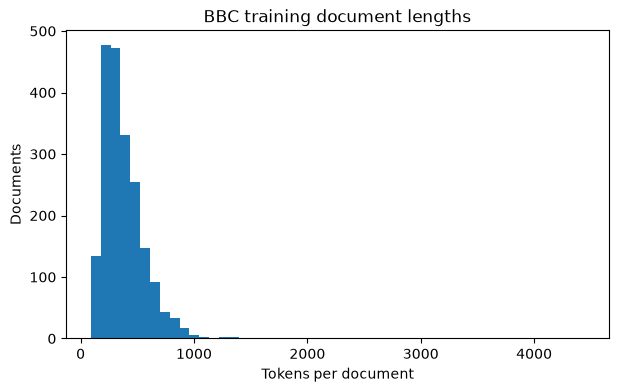

In [12]:
seq_lens = [len(s) for s in sequences_train]
print('Average sequence length:', round(np.mean(seq_lens), 1))
print('Maximum sequence length:', max(seq_lens))
plt.figure(figsize=(7, 4))
plt.hist(seq_lens, bins=50)
plt.xlabel('Tokens per document')
plt.ylabel('Documents')
plt.title('BBC training document lengths')
plt.show()

Documents vary in length. Padding and truncation produce a fixed rectangular input. Index 0 is reserved for padding, so we enable `mask_zero=True` for the average-pooling baseline to prevent artificial padding from diluting document representations.

In [13]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

MAX_SEQUENCE_LENGTH = 1000
x_train = pad_sequences(sequences_train, maxlen=MAX_SEQUENCE_LENGTH,
                        padding='post', truncating='post')
x_test = pad_sequences(sequences_test, maxlen=MAX_SEQUENCE_LENGTH,
                       padding='post', truncating='post')
y_train = to_categorical(target_train, num_classes=len(target_names))
y_test = to_categorical(target_test, num_classes=len(target_names))
N_CLASSES = len(target_names)
print('x_train / x_test:', x_train.shape, x_test.shape)
print('y_train / y_test:', y_train.shape, y_test.shape)
assert x_train.max() < MAX_NB_WORDS
assert y_train.shape[1] == N_CLASSES

x_train / x_test: (2025, 1000) (200, 1000)
y_train / y_test: (2025, 5) (200, 5)


## 4. A simple supervised CBOW model with learned embeddings

`Embedding → GlobalAveragePooling1D → Dense(softmax)` learns a word representation and averages the representations into one document vector. The final Dense layer predicts probabilities for five classes.

In [14]:
from tensorflow.keras.layers import Input, Dense, Embedding, GlobalAveragePooling1D
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

EMBEDDING_DIM = 50
cbow_model = Sequential([
    Input(shape=(MAX_SEQUENCE_LENGTH,)),
    Embedding(input_dim=MAX_NB_WORDS, output_dim=EMBEDDING_DIM, mask_zero=True),
    GlobalAveragePooling1D(),
    Dense(N_CLASSES, activation='softmax'),
], name='learned_embeddings_cbow')
cbow_model.compile(loss='categorical_crossentropy',
                   optimizer=Adam(learning_rate=0.01),
                   metrics=['accuracy'])
cbow_model.summary()

Model: "learned_embeddings_cbow"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 1000, 50)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 50)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           255 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,000,255 (3.82 MB)

 Trainable params: 1,000,255 (3.82 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
cbow_history = cbow_model.fit(x_train, y_train, validation_split=0.1,
                              epochs=10, batch_size=32, verbose=2)
cbow_loss, cbow_accuracy = cbow_model.evaluate(x_test, y_test, verbose=0)
print(f'CBOW test loss: {cbow_loss:.4f}')
print(f'CBOW test accuracy: {cbow_accuracy:.2%}')

Epoch 1/10
57/57 - 4s - 63ms/step - accuracy: 0.7903 - loss: 0.8879 - val_accuracy: 0.9310 - val_loss: 0.3042
Epoch 2/10
57/57 - 2s - 31ms/step - accuracy: 0.9874 - loss: 0.1022 - val_accuracy: 0.9557 - val_loss: 0.1729
Epoch 3/10
57/57 - 2s - 31ms/step - accuracy: 0.9989 - loss: 0.0280 - val_accuracy: 0.9557 - val_loss: 0.1593
Epoch 4/10
57/57 - 2s - 35ms/step - accuracy: 1.0000 - loss: 0.0123 - val_accuracy: 0.9557 - val_loss: 0.1588
Epoch 5/10
57/57 - 2s - 32ms/step - accuracy: 1.0000 - loss: 0.0071 - val_accuracy: 0.9557 - val_loss: 0.1607
Epoch 6/10
57/57 - 2s - 33ms/step - accuracy: 1.0000 - loss: 0.0047 - val_accuracy: 0.9557 - val_loss: 0.1626
Epoch 7/10
57/57 - 2s - 35ms/step - accuracy: 1.0000 - loss: 0.0033 - val_accuracy: 0.9557 - val_loss: 0.1643
Epoch 8/10
57/57 - 2s - 36ms/step - accuracy: 1.0000 - loss: 0.0025 - val_accuracy: 0.9557 - val_loss: 0.1662
Epoch 9/10
57/57 - 2s - 38ms/step - accuracy: 1.0000 - loss: 0.0020 - val_accuracy: 0.9557 - val_loss: 0.1680
Epoch 10/1

## Exercise 1 — Evaluate CBOW and display a misclassified BBC article

**Official task:** Evaluate the model on the test set; identify a misclassified document and display its text. The next two cells implement both steps and handle the case where no documents are misclassified.

CBOW test accuracy (manual): 96.50%
               precision    recall  f1-score   support

     business       0.98      0.91      0.94        46
entertainment       0.95      1.00      0.97        35
     politics       0.97      0.95      0.96        37
        sport       1.00      1.00      1.00        46
         tech       0.92      0.97      0.95        36

     accuracy                           0.96       200
    macro avg       0.96      0.97      0.96       200
 weighted avg       0.97      0.96      0.96       200



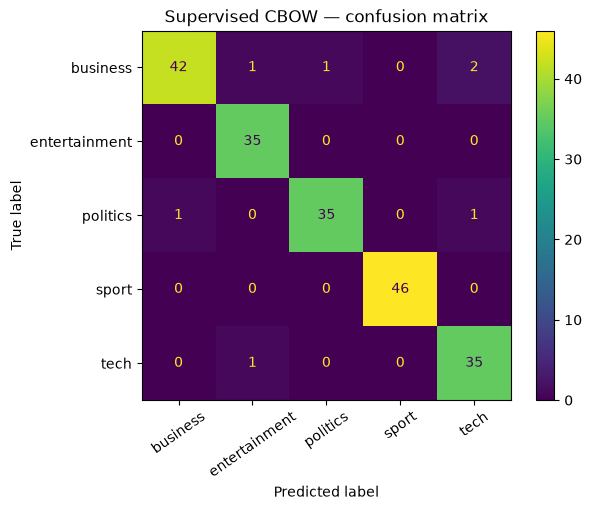

In [16]:
# EXERCISE 1A: independent test-set metrics and confusion matrix.
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix

predicted_probabilities = cbow_model.predict(x_test, batch_size=32, verbose=0)
predicted_classes = np.argmax(predicted_probabilities, axis=1)
computed_accuracy = np.mean(predicted_classes == target_test)
print(f'CBOW test accuracy (manual): {computed_accuracy:.2%}')
print(classification_report(target_test, predicted_classes,
                            target_names=target_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(target_test, predicted_classes,
                                        display_labels=target_names, xticks_rotation=35)
plt.title('Supervised CBOW — confusion matrix')
plt.show()
assert np.isclose(computed_accuracy, cbow_accuracy)

In [17]:
# EXERCISE 1B: show a genuinely misclassified news document from the TEST set.
wrong_indices = np.flatnonzero(predicted_classes != target_test)
print('Number of misclassified test documents:', len(wrong_indices))

if len(wrong_indices) > 0:
    # Show the mistake for which the model was most confident.
    wrong_confidences = predicted_probabilities[wrong_indices, predicted_classes[wrong_indices]]
    index = int(wrong_indices[np.argmax(wrong_confidences)])
    print('Test document index:', index)
    print('True class:', target_names[target_test[index]])
    print('Predicted class:', target_names[predicted_classes[index]])
    print('Confidence:', float(predicted_probabilities[index, predicted_classes[index]]))
    print('Predicted distribution:', {target_names[i]: round(float(p), 3)
                                       for i, p in enumerate(predicted_probabilities[index])})
    print('File:', filenames_test[index])
    print('\n--- FULL MISCLASSIFIED ARTICLE ---\n')
    print(texts_test[index])
else:
    print('No errors in this test set. Re-run with another seed to study errors.')

Number of misclassified test documents: 7
Test document index: 10
True class: business
Predicted class: tech
Confidence: 0.9117096662521362
Predicted distribution: {'business': 0.007, 'entertainment': 0.043, 'politics': 0.033, 'sport': 0.007, 'tech': 0.912}
File: bbc/business/243.txt

--- FULL MISCLASSIFIED ARTICLE ---

Making your office work for you

Our mission to brighten up your working lives continues - and this time, we're taking a long hard look at your offices.

Over the next few months, our panel of experts will be listening to your gripes about where you work, and suggesting ways to make your workspace more efficient, more congenial or simply prettier. This week, we're hearing from Marianne Petersen, who is planning to convert a barn in Sweden into a base for her freelance writing work. Click on the link under her photograph to read her story, and then scroll down to see what the panel have to say. And if you want to take part in the series, go to the bottom of the story to 

**Exercise 1 — Written answer:** The confusion matrix and classification report quantify performance on the previously unseen test documents. The error example is automatically chosen from **actual misclassifications**, rather than an invented text. Topic classification mistakes can occur because articles contain vocabulary associated with multiple categories; one article about a technology firm's financial results might naturally mix *tech* and *business* words. Whether that explains the printed example must be evaluated after inspecting its full text. Confidence is not proof of correctness.

## 5. Exercise 2 — Build a more complex text classifier

**Official task:** Copy the simple model and add complexity (for example `LSTM`, `Conv1D`, or additional dense layers). Here, a `Conv1D` neural network looks for local 5-word patterns and a `GlobalMaxPooling1D` layer gathers the strongest features. This is faster on a CPU than a large LSTM on 1000-token documents. We use Dropout to limit overfitting.

In [18]:
from tensorflow.keras.layers import Conv1D, GlobalMaxPooling1D, Dropout

complex_model = Sequential([
    Input(shape=(MAX_SEQUENCE_LENGTH,)),
    Embedding(input_dim=MAX_NB_WORDS, output_dim=64),
    Conv1D(filters=64, kernel_size=5, activation='relu', padding='same'),
    GlobalMaxPooling1D(),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(N_CLASSES, activation='softmax'),
], name='conv1d_text_classifier')
complex_model.compile(loss='categorical_crossentropy',
                      optimizer=Adam(learning_rate=0.001),
                      metrics=['accuracy'])
complex_model.summary()

Model: "conv1d_text_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 1000, 64)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 1000, 64)       │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,305,029 (4.98 MB)

 Trainable params: 1,305,029 (4.98 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
complex_history = complex_model.fit(x_train, y_train, validation_split=0.1,
                                    epochs=10, batch_size=32, verbose=2)
complex_loss, complex_accuracy = complex_model.evaluate(x_test, y_test, verbose=0)
complex_probs = complex_model.predict(x_test, verbose=0)
complex_predictions = np.argmax(complex_probs, axis=1)
print(f'Conv1D test loss: {complex_loss:.4f}')
print(f'Conv1D test accuracy: {complex_accuracy:.2%}')
print(classification_report(target_test, complex_predictions,
                            target_names=target_names, zero_division=0))

Epoch 1/10
57/57 - 8s - 141ms/step - accuracy: 0.3035 - loss: 1.5781 - val_accuracy: 0.5320 - val_loss: 1.5042
Epoch 2/10
57/57 - 5s - 86ms/step - accuracy: 0.5950 - loss: 1.2074 - val_accuracy: 0.7882 - val_loss: 0.9245
Epoch 3/10
57/57 - 5s - 92ms/step - accuracy: 0.8666 - loss: 0.5400 - val_accuracy: 0.8768 - val_loss: 0.4182
Epoch 4/10
57/57 - 5s - 91ms/step - accuracy: 0.9583 - loss: 0.1939 - val_accuracy: 0.9064 - val_loss: 0.2752
Epoch 5/10
57/57 - 5s - 91ms/step - accuracy: 0.9945 - loss: 0.0682 - val_accuracy: 0.9163 - val_loss: 0.2189
Epoch 6/10
57/57 - 6s - 99ms/step - accuracy: 0.9984 - loss: 0.0310 - val_accuracy: 0.9212 - val_loss: 0.2025
Epoch 7/10
57/57 - 5s - 96ms/step - accuracy: 1.0000 - loss: 0.0157 - val_accuracy: 0.9310 - val_loss: 0.1919
Epoch 8/10
57/57 - 6s - 109ms/step - accuracy: 0.9995 - loss: 0.0126 - val_accuracy: 0.9261 - val_loss: 0.2012
Epoch 9/10
57/57 - 7s - 117ms/step - accuracy: 1.0000 - loss: 0.0083 - val_accuracy: 0.9261 - val_loss: 0.2062
Epoch 1

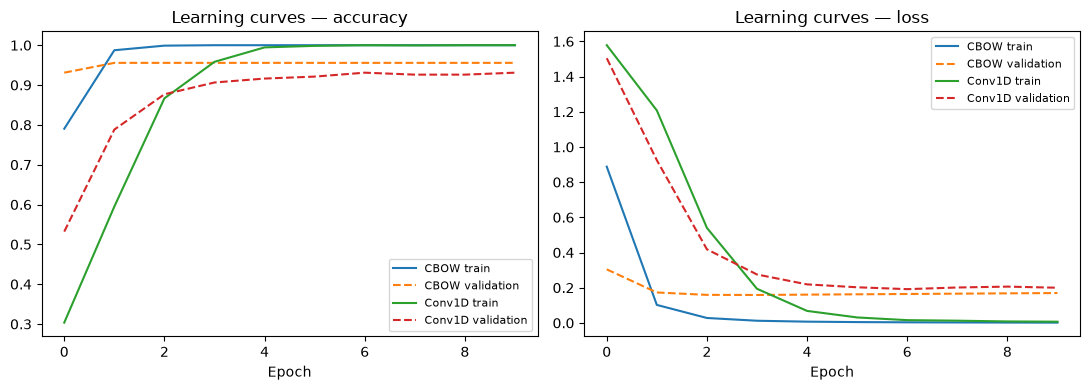

Accuracy difference (Conv1D minus CBOW): -1.00 percentage points


In [20]:
# Compare training/validation accuracy without assuming either model wins.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for title, history in [('CBOW', cbow_history), ('Conv1D', complex_history)]:
    axes[0].plot(history.history['accuracy'], label=f'{title} train')
    axes[0].plot(history.history['val_accuracy'], '--', label=f'{title} validation')
    axes[1].plot(history.history['loss'], label=f'{title} train')
    axes[1].plot(history.history['val_loss'], '--', label=f'{title} validation')
axes[0].set_title('Learning curves — accuracy')
axes[1].set_title('Learning curves — loss')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print('Accuracy difference (Conv1D minus CBOW):',
      f'{(complex_accuracy-cbow_accuracy)*100:+.2f} percentage points')

**Exercise 2 — Written answer:** The Conv1D model can detect local word-order patterns that simple averaging loses, but it has more parameters and may overfit on a small corpus. The two training/validation curves above reveal whether accuracy improves or the validation loss starts to rise. The test-accuracy difference is computed from the actual run; it would be inaccurate to claim Conv1D must be better. A third possible approach is an LSTM, which models order over longer ranges but generally costs more CPU time.

## 6. Loading pretrained GloVe embeddings

The original lab uses `glove100K.100d.txt`, a 100-dimensional GloVe extract containing approximately 100,000 common words. Its ZIP is downloaded from the course's specified GitHub release. This is a **separate resource from BBC**, and the first download may take time.

In [21]:
URL_REPRESENTATIONS = (
    'https://github.com/m2dsupsdlclass/lectures-labs/releases/'
    'download/0.3/glove100k.100d.zip'
)
ZIP_REPRESENTATIONS = Path('glove100k.100d.zip')
FILE_REPRESENTATIONS = Path('glove100K.100d.txt')
if not FILE_REPRESENTATIONS.exists():
    if not ZIP_REPRESENTATIONS.exists():
        try:
            print('Downloading GloVe extract:', URL_REPRESENTATIONS)
            urlretrieve(URL_REPRESENTATIONS, ZIP_REPRESENTATIONS)
        except Exception as exc:
            if ZIP_REPRESENTATIONS.exists():
                ZIP_REPRESENTATIONS.unlink()
            raise RuntimeError(
                'GloVe download failed. Download the archive manually from '
                'the URL in URL_REPRESENTATIONS and place it beside this notebook.'
            ) from exc
    with zipfile.ZipFile(ZIP_REPRESENTATIONS) as archive:
        safe_root = Path.cwd().resolve()
        for member in archive.infolist():
            if not (safe_root / member.filename).resolve().is_relative_to(safe_root):
                raise ValueError('Unsafe path in GloVe archive')
        archive.extractall(safe_root)
if not FILE_REPRESENTATIONS.exists():
    raise FileNotFoundError('GloVe text file not found after extracting ZIP')
print('GloVe file:', FILE_REPRESENTATIONS.resolve())

GloVe file: /Users/lvsburgerl/Documents/UOFT DSI MACHINE LEARNING FALL 2026/deep_learning/01_materials/labs/glove100K.100d.txt


In [22]:
# Parse GloVe vectors. Each line starts with the word followed by 100 float values.
embeddings_index = {}
embeddings_vectors = []
with FILE_REPRESENTATIONS.open('rb') as f:
    for line in f:
        fields = line.decode('utf-8').split()
        if len(fields) != 101:
            continue
        word, vector_values = fields[0], fields[1:]
        embeddings_index[word] = len(embeddings_vectors)
        embeddings_vectors.append(np.asarray(vector_values, dtype='float32'))

inv_index = {i: word for word, i in embeddings_index.items()}
glove_embeddings = np.vstack(embeddings_vectors).astype('float32')
glove_norms = np.linalg.norm(glove_embeddings, axis=-1, keepdims=True)
glove_embeddings_normed = glove_embeddings / np.maximum(glove_norms, 1e-12)
print('Found', len(embeddings_index), 'words')
print('GloVe shape:', glove_embeddings.shape)
assert glove_embeddings.shape[1] == 100

Found 100000 words
GloVe shape: (100000, 100)


In [23]:
def get_emb(word):
    idx = embeddings_index.get(word)
    return None if idx is None else glove_embeddings[idx]

def get_normed_emb(word):
    idx = embeddings_index.get(word)
    return None if idx is None else glove_embeddings_normed[idx]

print('Embedding for "computer":', get_emb('computer'))
print('Shape:', get_emb('computer').shape if get_emb('computer') is not None else None)

Embedding for "computer": [-1.6298e-01  3.0141e-01  5.7978e-01  6.6548e-02  4.5835e-01 -1.5329e-01
  4.3258e-01 -8.9215e-01  5.7747e-01  3.6375e-01  5.6524e-01 -5.6281e-01
  3.5659e-01 -3.6096e-01 -9.9662e-02  5.2753e-01  3.8839e-01  9.6185e-01
  1.8841e-01  3.0741e-01 -8.7842e-01 -3.2442e-01  1.1202e+00  7.5126e-02
  4.2661e-01 -6.0651e-01 -1.3893e-01  4.7862e-02 -4.5158e-01  9.3723e-02
  1.7463e-01  1.0962e+00 -1.0044e+00  6.3889e-02  3.8002e-01  2.1109e-01
 -6.6247e-01 -4.0736e-01  8.9442e-01 -6.0974e-01 -1.8577e-01 -1.9913e-01
 -6.9226e-01 -3.1806e-01 -7.8565e-01  2.3831e-01  1.2992e-01  8.7721e-02
  4.3205e-01 -2.2662e-01  3.1549e-01 -3.1748e-01 -2.4632e-03  1.6615e-01
  4.2358e-01 -1.8087e+00 -3.6699e-01  2.3949e-01  2.5458e+00  3.6111e-01
  3.9486e-02  4.8607e-01 -3.6974e-01  5.7282e-02 -4.9317e-01  2.2765e-01
  7.9966e-01  2.1428e-01  6.9811e-01  1.1262e+00 -1.3526e-01  7.1972e-01
 -9.9605e-04 -2.6842e-01 -8.3038e-01  2.1780e-01  3.4355e-01  3.7731e-01
 -4.0251e-01  3.3124e-01 

### Finding most similar words using cosine similarity

The original notebook experiments with queries such as `cpu`, `nvidia`, and a combination of `toronto` and `leaf`. We retain them and handle words absent from the GloVe vocabulary gracefully.

In [24]:
def most_similar(words, topn=10):
    if isinstance(words, str):
        words = [words]
    vectors = []
    for word in words:
        vec = get_emb(word)
        if vec is None:
            raise ValueError(f'Word not found in GloVe vocabulary: {word!r}')
        vectors.append(vec)
    query_emb = np.mean(vectors, axis=0)
    query_norm = np.linalg.norm(query_emb)
    if query_norm == 0:
        raise ValueError('Query vector is zero')
    query_emb /= query_norm
    cosine_scores = glove_embeddings_normed @ query_emb
    top_indices = np.argsort(cosine_scores)[::-1][:topn]
    return [(inv_index[int(idx)], float(cosine_scores[idx])) for idx in top_indices]

for query in ['cpu', 'nvidia', '1', ['toronto', 'leaf']]:
    try:
        print('\nQuery:', query)
        print(most_similar(query, topn=10))
    except ValueError as exc:
        print('Unavailable query:', exc)


Query: cpu
[('cpu', 0.9999999403953552), ('processor', 0.779343843460083), ('cpus', 0.7651844024658203), ('microprocessor', 0.7360633611679077), ('processors', 0.6734814643859863), ('motherboard', 0.6675772666931152), ('x86', 0.6655921936035156), ('pentium', 0.6475850343704224), ('gpu', 0.6448882222175598), ('i/o', 0.6352352499961853)]

Query: nvidia
[('nvidia', 1.0), ('geforce', 0.7025035619735718), ('gpu', 0.6787484884262085), ('ati', 0.6703709363937378), ('chipset', 0.6381311416625977), ('gpus', 0.6330379843711853), ('amd', 0.6098824143409729), ('chipsets', 0.6023343801498413), ('tesla', 0.5855021476745605), ('intel', 0.56317138671875)]

Query: 1
[('1', 1.0000001192092896), ('2', 0.971360445022583), ('3', 0.9551016092300415), ('4', 0.93552565574646), ('5', 0.9143884778022766), ('6', 0.901603639125824), ('8', 0.8834145069122314), ('7', 0.8745429515838623), ('9', 0.8470947742462158), ('10', 0.8159793019294739)]

Query: ['toronto', 'leaf']
[('leaf', 0.7868252992630005), ('toronto', 0.

**Interpretation:** A cosine similarity near +1 indicates similar directions in the embedding space, not necessarily strict synonyms. Word vectors learn statistical associations from their original training corpus. Combining two word vectors by averaging creates a crude semantic query, not a reliable literal combination of concepts.

### Visualizing GloVe word embeddings with t-SNE

The original lab uses the first 1000 words. We keep that sample size but annotate only the first 100 labels for readability; the plot still contains all 1000 points. Two-dimensional t-SNE coordinates are not true metric distances in the original 100-dimensional space.

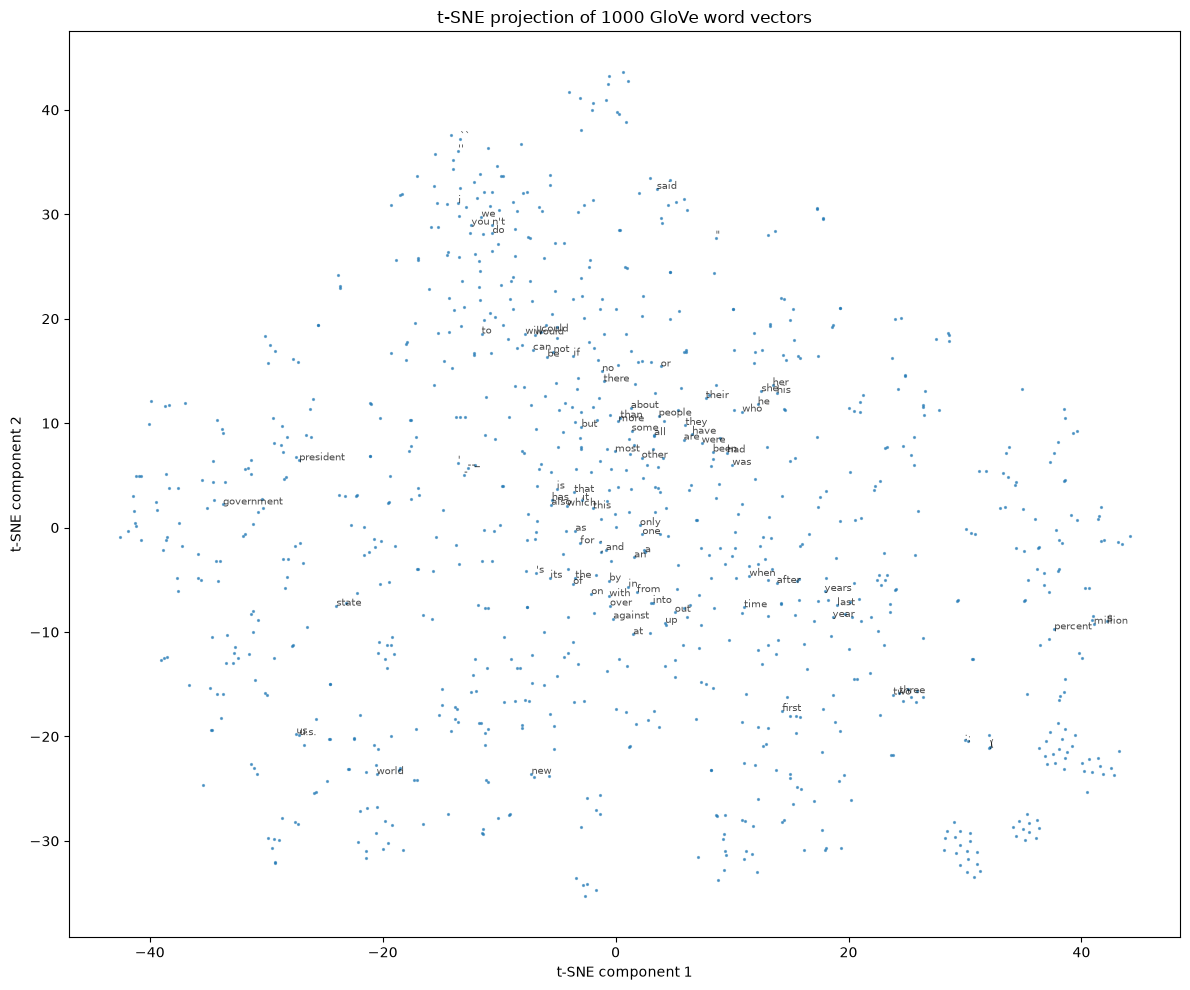

In [25]:
from sklearn.manifold import TSNE

N_TSNE = min(1000, len(glove_embeddings_normed))
word_emb_tsne = TSNE(
    n_components=2, perplexity=30, learning_rate='auto', init='pca',
    random_state=42
).fit_transform(glove_embeddings_normed[:N_TSNE])

fig, ax = plt.subplots(figsize=(12, 10))
ax.scatter(word_emb_tsne[:, 0], word_emb_tsne[:, 1], marker='.', s=7, alpha=0.6)
for idx in range(min(100, N_TSNE)):
    ax.annotate(inv_index[idx], xy=(word_emb_tsne[idx, 0], word_emb_tsne[idx, 1]),
                fontsize=7, alpha=0.7)
ax.set_title(f't-SNE projection of {N_TSNE} GloVe word vectors')
ax.set_xlabel('t-SNE component 1')
ax.set_ylabel('t-SNE component 2')
plt.tight_layout()
plt.savefig('lab6_glove_tsne.png', dpi=150)
plt.show()

## 7. Transfer learning — use pretrained embeddings for BBC classification

Create a 20,000×100 embedding matrix aligned to the BBC tokenizer IDs. Words missing from GloVe remain zeros, and index 0 is reserved for padding. Initialize a new Keras `Embedding` with this matrix and **freeze** it for the baseline pretrained experiment.

In [26]:
GLOVE_DIM = 100
embedding_matrix = np.zeros((MAX_NB_WORDS, GLOVE_DIM), dtype='float32')
matched_words = 0
for word, index in word_index.items():
    if index <= 0 or index >= MAX_NB_WORDS:
        continue
    pretrained_vector = get_emb(word)
    if pretrained_vector is not None:
        embedding_matrix[index] = pretrained_vector
        matched_words += 1

usable_words = sum(0 < index < MAX_NB_WORDS for index in word_index.values())
print(f'Matched BBC words in GloVe: {matched_words} / {usable_words}')
print('Embedding matrix:', embedding_matrix.shape)
assert embedding_matrix.shape == (MAX_NB_WORDS, 100)
assert np.all(embedding_matrix[0] == 0)

Matched BBC words in GloVe: 17298 / 19999
Embedding matrix: (20000, 100)


In [27]:
# Rebuild instead of reusing the trained CBOW layer.
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Input

pretrained_embedding_layer = Embedding(
    input_dim=MAX_NB_WORDS,
    output_dim=GLOVE_DIM,
    weights=[embedding_matrix],
    mask_zero=True,
    trainable=False,
    name='frozen_glove_embeddings',
)
pretrained_model = Sequential([
    Input(shape=(MAX_SEQUENCE_LENGTH,)),
    pretrained_embedding_layer,
    GlobalAveragePooling1D(),
    Dense(N_CLASSES, activation='softmax'),
], name='pretrained_glove_cbow')
pretrained_model.compile(loss='categorical_crossentropy',
                         optimizer=Adam(learning_rate=0.01),
                         metrics=['accuracy'])
pretrained_model.summary()
assert pretrained_embedding_layer.trainable is False

Model: "pretrained_glove_cbow"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ frozen_glove_embeddings         │ (None, 1000, 100)      │     2,000,000 │
│ (Embedding)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 100)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           505 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,000,505 (7.63 MB)

 Trainable params: 505 (1.97 KB)

 Non-trainable params: 2,000,000 (7.63 MB)

In [28]:
pretrained_history = pretrained_model.fit(
    x_train, y_train, validation_split=0.1, epochs=15,
    batch_size=32, verbose=2
)
pretrained_loss, pretrained_accuracy = pretrained_model.evaluate(
    x_test, y_test, verbose=0
)
print(f'Frozen GloVe test loss: {pretrained_loss:.4f}')
print(f'Frozen GloVe test accuracy: {pretrained_accuracy:.2%}')

Epoch 1/15
57/57 - 14s - 248ms/step - accuracy: 0.6959 - loss: 1.1971 - val_accuracy: 0.9163 - val_loss: 0.8236
Epoch 2/15
57/57 - 7s - 121ms/step - accuracy: 0.9149 - loss: 0.6481 - val_accuracy: 0.9064 - val_loss: 0.5262
Epoch 3/15
57/57 - 3s - 55ms/step - accuracy: 0.9341 - loss: 0.4435 - val_accuracy: 0.9064 - val_loss: 0.4012
Epoch 4/15
57/57 - 3s - 48ms/step - accuracy: 0.9429 - loss: 0.3465 - val_accuracy: 0.9163 - val_loss: 0.3376
Epoch 5/15
57/57 - 2s - 42ms/step - accuracy: 0.9451 - loss: 0.2906 - val_accuracy: 0.9212 - val_loss: 0.3003
Epoch 6/15
57/57 - 2s - 39ms/step - accuracy: 0.9495 - loss: 0.2541 - val_accuracy: 0.9212 - val_loss: 0.2759
Epoch 7/15
57/57 - 2s - 28ms/step - accuracy: 0.9539 - loss: 0.2282 - val_accuracy: 0.9212 - val_loss: 0.2589
Epoch 8/15
57/57 - 2s - 28ms/step - accuracy: 0.9539 - loss: 0.2088 - val_accuracy: 0.9261 - val_loss: 0.2463
Epoch 9/15
57/57 - 2s - 28ms/step - accuracy: 0.9544 - loss: 0.1936 - val_accuracy: 0.9360 - val_loss: 0.2366
Epoch 1

### Final comparison of all four text classification models

The results are calculated from the actual test runs. The table reports the Logistic Regression baseline and the three neural approaches; the narrative below is generated from observed scores.

In [29]:
import pandas as pd
results = pd.DataFrame([
    {'Model': 'CountVectorizer + Logistic Regression', 'Test accuracy': baseline_accuracy},
    {'Model': 'Supervised CBOW (trained embeddings)', 'Test accuracy': cbow_accuracy},
    {'Model': 'Conv1D + Dense + Dropout', 'Test accuracy': complex_accuracy},
    {'Model': 'CBOW with frozen pretrained GloVe', 'Test accuracy': pretrained_accuracy},
]).sort_values('Test accuracy', ascending=False)
display(results.style.format({'Test accuracy': '{:.2%}'}))
print('\nBest measured test-set accuracy:', results.iloc[0]['Model'],
      f"({results.iloc[0]['Test accuracy']:.2%})")
print('All models were evaluated on the same held-out BBC test documents.')
print('Caution: choose hyperparameters using validation data, not test accuracy.')

AttributeError: The '.style' accessor requires jinja2

### Final written answers and reality check

**What did I learn?** `CountVectorizer` and logistic regression are a simple but strong baseline for topic classification. Learned embeddings map sparse words to dense vectors. CBOW averaging summarizes the document while discarding exact order; Conv1D can capture local ordered phrases. GloVe transfers word representations learned on much larger external text, allowing training with fixed embeddings.

**Does deep learning necessarily improve on the baseline?** No. The BBC dataset is fairly small and topic labels often correlate with distinctive words. Bag-of-words methods can outperform a more complex network while training much faster. **The table above shows which approach actually performed best**; do not assume the neural model wins.

**Possible limitations:** The BBC corpus covers only five topics, news from an older period, and one English-language source. Scores on this dataset do not establish robustness on modern news or different document genres. Pretrained embeddings may miss terms and context; static GloVe assigns the same word vector regardless of its meaning in a sentence.

**Potential improvements:** Validation-based hyperparameter tuning; pretrained contextual embeddings (e.g., BERT); class-sensitive error inspection; and evaluation on an independent news source.

